In [5]:
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.append('../../code')
from utils import simulate_transient_waiting_time_gamma_exponential_queue, estimate_convergence_time
from utils import simulate_single_server_queue_from_times
from tqdm import tqdm

<div dir="rtl">

## מתי תחכו יותר? 

### בתור לקפיטריה ב12:00 או ב16:00? 

### בכביש איילון ב08:00 או ב22:00?

### עד עכשיו הסתכלנו על זמן המתנה כאילו הוא קבוע בזמן אבל האמנם?

### זוכרים שלמדתם סטוכסטיים? 

### מצטער, אבל אנחנו חוזרים בדיוק לשם :(

### בסטוכסטיים דיברנו על מושג שקוראים לו ארגודיות. מה זה אומר?

### זה אומר שמדדי התור כמו התפלגות זמני המתנה או אורך תור לא משתנים עם הזמן?

### מתי זה קורה?

## 1. שנצילות התור קטנה מ-1.
## 2. שהתפלגויות ההגעה והשירות קבועות בזמן. 

## נצילות: פרופורציות הזמן שהתור תפוס: 

### מחושב לפי:

## $$ \lambda E[S] $$

## כאשר $\lambda$ זה קצה הגעה.
## $E[S]$ זה תוחלת זמן שירות

### בסטוכסטיים למדנו שכאשר יש לנו שרשרת מרקוב שהיא ארגודית - הסתברויות מצב יציב מגיעים אליהם רק אחרי כמה סיבובים.

### אותו דבר גם כאן: לוקח לנו זמן להגיע להתייצבות של המדדים.

### נסמלץ מערכת תורים שזמנים בין הגעה ושירות מפולגים מעריכית, כאשר קצב הגעה הוא 0.8 וקצב שירות הוא 1. 

### נראה את תוחלת זמן המתנה כפונקציה של הזמן:




In [39]:
import simpy
import numpy as np


def customer(env, server, service_rate):
    """A single customer."""
    with server.request() as req:
        yield req

        service_time = np.random.exponential(1 / service_rate)
        yield env.timeout(service_time)


def arrival_process(env, server, arrival_rate, service_rate):
    """Generate customers according to a Poisson process."""
    while True:
        interarrival_time = np.random.exponential(1 / arrival_rate)
        yield env.timeout(interarrival_time)

        env.process(customer(env, server, service_rate))


def simulate_one_replication(
    simulation_time=1000,
    arrival_rate=0.8,
    service_rate=1.0
):
    """
    Simulate one M/M/1 queue.

    Returns
    -------
    num_in_system : numpy array
        N(t) at t = 1, 2, ..., simulation_time.
    """

    env = simpy.Environment()
    server = simpy.Resource(env, capacity=1)

    env.process(
        arrival_process(
            env,
            server,
            arrival_rate,
            service_rate
        )
    )

    num_in_system = np.zeros(simulation_time)

    for t in range(1, simulation_time + 1):

        env.run(until=t)

        # Customers waiting + customer currently in service
        num_in_system[t - 1] = len(server.queue) + server.count

    return num_in_system


def stationary_diagnostic_simulation(
    n_replications=5000,
    simulation_time=1000,
    arrival_rate=0.8,
    service_rate=1.0,
    seed=1234
):
    """
    Run independent M/M/1 simulations and calculate
    E[N(t)] across replications.
    """

    np.random.seed(seed)

    mean_num_in_system = np.zeros(simulation_time)

    for rep in range(n_replications):

        trajectory = simulate_one_replication(
            simulation_time=simulation_time,
            arrival_rate=arrival_rate,
            service_rate=service_rate
        )

        mean_num_in_system += trajectory

    mean_num_in_system /= n_replications

    return mean_num_in_system

In [40]:
mean_N = stationary_diagnostic_simulation(
    n_replications=5000,
    simulation_time=1000,
    arrival_rate=0.8,
    service_rate=1.0
)

print(mean_N.shape)

(1000,)


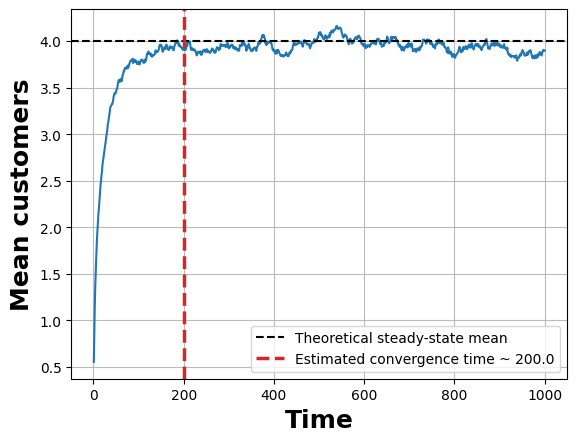

In [65]:
plt.figure()
plt.plot(np.arange(mean_N.shape[0])+1, mean_N)
plt.grid(alpha=0.85)
plt.xlabel('Time', fontsize = 18, fontweight = 'bold')
plt.ylabel('Mean customers', fontsize = 18, fontweight = 'bold')

plt.axhline(
    y=0.8 / (1 - 0.8),
    linestyle="--",
    label="Theoretical steady-state mean",
    color = 'black'
)

plt.axvline(
        200,
        color="tab:red",
        linestyle="--",
        linewidth=2.5,
        label=f"Estimated convergence time ~ {200:.1f}",
    )
plt.legend()
plt.savefig('convergence_5000_replications.png')
plt.show()

In [50]:
mean_N_large_replications = stationary_diagnostic_simulation(
    n_replications=25000,
    simulation_time=1000,
    arrival_rate=0.8,
    service_rate=1.0
)

print(mean_N_large_replications.shape)

(1000,)


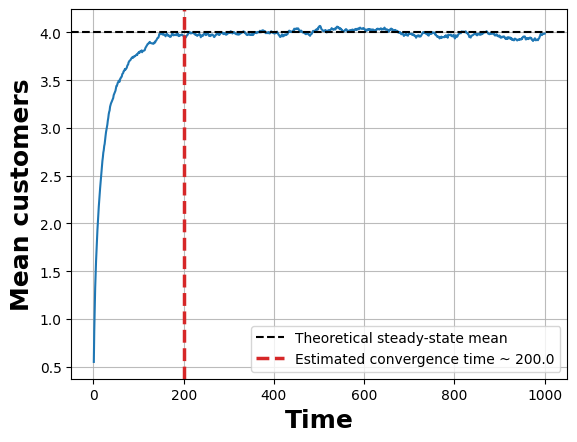

In [64]:
plt.figure()
plt.plot(np.arange(mean_N_large_replications.shape[0])+1, mean_N_large_replications)
plt.grid(alpha=0.85)
plt.xlabel('Time', fontsize = 18, fontweight = 'bold')
plt.ylabel('Mean customers', fontsize = 18, fontweight = 'bold')

plt.axhline(
    y=0.8 / (1 - 0.8),
    linestyle="--",
    label="Theoretical steady-state mean",
    color = 'black'
)

plt.axvline(
        200,
        color="tab:red",
        linestyle="--",
        linewidth=2.5,
        label=f"Estimated convergence time ~ {200:.1f}",
    )
plt.legend()
plt.savefig('convergence_25000_replications.png')
plt.show()

<div dir="rtl">

## השפעת כמות החזרות על הדיוק:

### בדוגמא הקודמת עשינו הרצה של 5000 הרצות.

### עכשיו אנחנו עושים 25000 חזרות. מה שניתן לראות בהבדל הוא שהפעם הגרף פחות רועש.

## למה זה קורה?


### כשאנחנו מריצים יותר חזרות האומד שלנו עם שונות קטנה יותר ולכן פחות רועש.

### שאלה למחשבה: מה יקרה אם היינו עושים 1,000,000,000 חזרות? כיצד הגרף היה נראה?


<div dir="rtl">

### הניתוח עזר לנו למצוא את הנקודה בזמן הזה.

### מה זה אומר?

### אם נעשה סימולציה וננתח את הפאזה הסטציונרית - לא נתייחס לערכים בשלב הטרנזיאנטי. 

### קוראים לתקופה הזאת warm-up period בספרות

### אם זה מתכנס למה זה לא קו ישר בדיוק?

### זה פשוט עניין של ממוצע של כמה זמן אחורה אנחנו לוקחים. 

### בדוגמה לעיל לקחנו 50000 אם ניקח נגיד 200000 כלומר פי 4 זה ייראה הרבה יותר מדויק.



In [53]:
mean_N_non_stationay = stationary_diagnostic_simulation(
    n_replications=5000,
    simulation_time=1000,
    arrival_rate=1.1,
    service_rate=1.0
)

print(mean_N_non_stationay.shape)

(1000,)


<div dir="rtl">

## ואם תנאי יציבות לא מתקיים:

### נבדוק שני מקרים.

### 1. הנצילות גדלה מ-1 אך המערכת קבועה בזמן.

### 2. הנצילות לא גדולה מ-1 אך משתנה עם הזמן

### תחילה נראה מה קורה במקרה 1: פה קצב ההגעה הוא 1.1 ולכן הנצילות גדולה מ-1 כאשר קצב השירות נשאר 1



C:\Users\Eshel\AppData\Local\Temp\ipykernel_46052\869575985.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


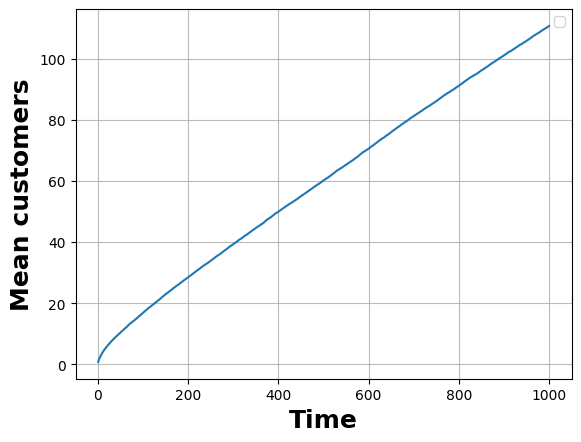

In [66]:
plt.figure()
plt.plot(np.arange(mean_N_non_stationay.shape[0])+1, mean_N_non_stationay)
plt.grid(alpha=0.85)
plt.xlabel('Time', fontsize = 18, fontweight = 'bold')
plt.ylabel('Mean customers', fontsize = 18, fontweight = 'bold')




plt.legend()
plt.savefig('non_convergence_5000_replications.png')
plt.show()

<div dir="rtl">

## רואים פשוט שהתוחלת מספר הצרכנים במערכת פשוט גדלה עם הזמן. וזה יהיה כך לנצח נצחים.


### עכשיו נוציא גרף עבור מערכת שאמנם הנצילות שלה לא גדולה מ-1 בשום שלב בזמן אבל משתנה עם הזמן

In [59]:
import simpy
import numpy as np
import matplotlib.pyplot as plt


def arrival_rate(t, period=100):
    """
    Time-dependent arrival rate.
    
    Oscillates between 0.7 and 0.9.
    """
    return 0.8 - 0.1 * np.cos(2 * np.pi * t / period)


def customer(env, server, service_rate):
    """A single customer."""
    
    with server.request() as req:
        yield req

        service_time = np.random.exponential(1 / service_rate)
        yield env.timeout(service_time)


def arrival_process(env, server, service_rate, period=100):
    """
    Generate arrivals from a nonhomogeneous Poisson process
    using thinning.
    """

    lambda_max = 0.9

    while True:

        # Candidate arrival from a Poisson process with rate lambda_max
        interarrival_time = np.random.exponential(1 / lambda_max)

        yield env.timeout(interarrival_time)

        # Current arrival rate
        lambda_t = arrival_rate(env.now, period)

        # Accept candidate with probability lambda(t) / lambda_max
        if np.random.rand() < lambda_t / lambda_max:

            env.process(
                customer(
                    env,
                    server,
                    service_rate
                )
            )


def simulate_one_replication(
    simulation_time=1000,
    service_rate=1.0,
    period=100
):
    """
    Simulate one Mt/M/1 queue.

    Returns
    -------
    num_in_system : numpy array
        N(t) at t = 1, ..., simulation_time.
    """

    env = simpy.Environment()

    server = simpy.Resource(
        env,
        capacity=1
    )

    env.process(
        arrival_process(
            env,
            server,
            service_rate,
            period
        )
    )

    num_in_system = np.zeros(simulation_time)

    for t in range(1, simulation_time + 1):

        env.run(until=t)

        # waiting + in service
        num_in_system[t - 1] = (
            len(server.queue) + server.count
        )

    return num_in_system


def run_experiment(
    n_replications=5000,
    simulation_time=1000,
    service_rate=1.0,
    period=100,
    seed=1234
):

    np.random.seed(seed)

    mean_num_in_system = np.zeros(simulation_time)

    for rep in range(n_replications):

        trajectory = simulate_one_replication(
            simulation_time=simulation_time,
            service_rate=service_rate,
            period=period
        )

        mean_num_in_system += trajectory

    mean_num_in_system /= n_replications

    return mean_num_in_system

mean_num_in_system = run_experiment()

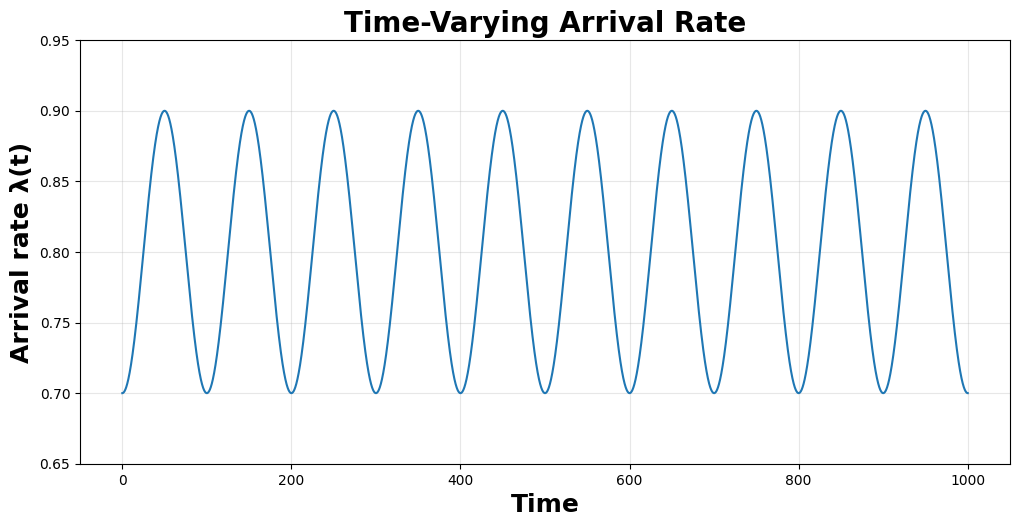

In [69]:
import numpy as np
import matplotlib.pyplot as plt


def arrival_rate(t, period=100):
    return 0.8 - 0.1 * np.cos(2 * np.pi * t / period)


# Time points
t = np.linspace(0, 1000, 10000)

# Arrival rate at each time
lambda_t = arrival_rate(t, period=100)


plt.figure(figsize=(12, 5.5))

plt.plot(t, lambda_t)

plt.xlabel("Time", fontsize = 18, fontweight = 'bold')
plt.ylabel("Arrival rate λ(t)", fontsize = 18, fontweight = 'bold')
plt.title("Time-Varying Arrival Rate", fontsize = 20, fontweight = 'bold')

plt.ylim(0.65, 0.95)
plt.grid(alpha=0.3)
plt.savefig('arrival_rate_time_invariant_5000_replications.png')

plt.show()

C:\Users\Eshel\AppData\Local\Temp\ipykernel_46052\1559682910.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


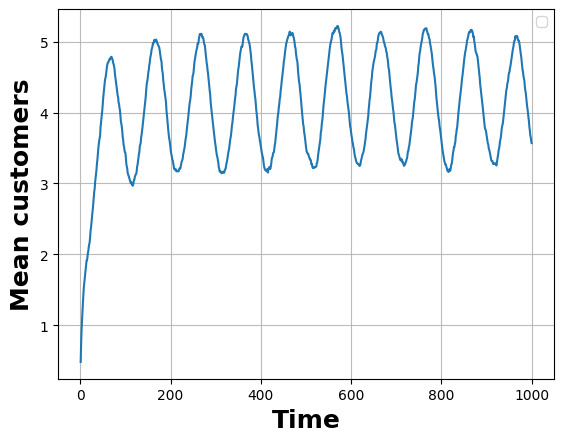

In [67]:
plt.figure()
plt.plot(np.arange(mean_num_in_system.shape[0])+1, mean_num_in_system)
plt.grid(alpha=0.85)
plt.xlabel('Time', fontsize = 18, fontweight = 'bold')
plt.ylabel('Mean customers', fontsize = 18, fontweight = 'bold')




plt.legend()
plt.savefig('non_convergence_time_invariant_5000_replications.png')
plt.show()

<div dir="rtl">

## רואים פשוט שהתוחלת מספר הצרכנים במערכת פשוט גדלה עם הזמן. וזה יהיה כך לנצח נצחים.


### הערה פרקטית: מציאת הנקודה בדיוק לא מאד חשובה. מ-2 סיבות:

### 1. אם ניקח נקודה יותר מאוחרת אז בעצם זרקנו קצת נקודות סימולציה. אבל המחשבים של היום מסמלצים יחסית מהר אז אם נזרוק 10000 יחידות זמן זה זניח.

### 2. אם ניקח נקודה קצת מוקמת מדי כלומר נתחשב גם בערכים שלא מגיעים מההתפלגות שיווי משקל האמיתית אבל אז נחשב את זה יחד עם כל שאר הערכים שכן הגיעו אז זה יגרום לשגיאה קטנה מאד. 

### למשל אם נחשב ממוצע זמן המתנה של עוד 5000 ערכים בשלב הטרזיאנטי יחד עם 3000000 של השלב הסטציונארי ה5000 ערכים האלו ישפיעו ממש מעט.

### כלל אצבע: פשוט נזרוק את ה5000 הערכים הראשונים.

### במערכות תורים גדולים יותר - אם יש יותר מ-5 תחנות הwarm-up perdiod יהיה 20000